## 1. BigQuery 데이터 불러오기

Google Colab에서 BigQuery에 직접 연결하여 사용자별 집계 데이터(User DM)를 불러온다.

### 데이터 조회 과정
1. BigQuery 및 Pandas 라이브러리 설치
2. 필요한 라이브러리 불러오기
3. Google 계정 인증
4. BigQuery 클라이언트 생성
5. SQL 쿼리를 실행하여 User DM 조회
6. 조회 결과를 Pandas DataFrame으로 변환

### 데이터 정보
- **프로젝트 ID:** `public-data-513413`
- **데이터셋:** `ga4_ecommerce`
- **테이블:** `user_dm`
- **분석 단위:** 사용자 1명당 1행

BigQuery에서 조회한 데이터를 Pandas DataFrame으로 변환하여 이후 데이터 탐색 및 통계 분석에 활용한다.

In [ ]:
# 1. 라이브러리 설치
!pip install -q google-cloud-bigquery pandas db-dtypes

# 2. 라이브러리 불러오기
from google.colab import auth
from google.cloud import bigquery
import pandas as pd

# 3. Google 계정 인증
auth.authenticate_user()

# 4. BigQuery 클라이언트 생성
project_id = "public-data-513413"

client = bigquery.Client(project=project_id)

# 5. BigQuery 테이블 조회
query = """
SELECT *
FROM `public-data-513413.ga4_ecommerce.user_dm`
"""

df = client.query(query).to_dataframe()

print("데이터 불러오기 완료!")

데이터 불러오기 완료!


## 2. 데이터 구조 확인

데이터의 크기, 컬럼별 자료형, 결측치 및 중복 여부를 확인한다.

In [ ]:
# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 컬럼 및 데이터 타입 확인
df.info()

# 결측치 확인
print(df.isnull().sum())

# 중복 데이터 확인
print("중복 행 수:", df.duplicated().sum())

데이터 크기: (270154, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 270154 entries, 0 to 270153
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_pseudo_id     270154 non-null  object
 1   total_events       270154 non-null  Int64 
 2   view_item_count    270154 non-null  Int64 
 3   add_to_cart_count  270154 non-null  Int64 
 4   purchase_count     270154 non-null  Int64 
 5   purchase_flag      270154 non-null  Int64 
 6   first_event_date   270154 non-null  dbdate
dtypes: Int64(5), dbdate(1), object(1)
memory usage: 15.7+ MB
user_pseudo_id       0
total_events         0
view_item_count      0
add_to_cart_count    0
purchase_count       0
purchase_flag        0
first_event_date     0
dtype: int64
중복 행 수: 0


## 3. 기술통계 분석

사용자별 이벤트 발생 횟수의 분포와 기본적인 통계적 특성을 확인한다.

분석 변수:
- total_events
- view_item_count
- add_to_cart_count
- purchase_count

In [ ]:
event_columns = [
    'total_events',
    'view_item_count',
    'add_to_cart_count',
    'purchase_count'
]

df[event_columns].describe().round(2)

,total_events,view_item_count,add_to_cart_count,purchase_count
count,270154.0,270154.0,270154.0,270154.0
mean,15.9,1.43,0.22,0.02
std,39.03,6.44,1.8,0.2
min,1.0,0.0,0.0,0.0
25%,4.0,0.0,0.0,0.0
50%,6.0,0.0,0.0,0.0
75%,11.0,0.0,0.0,0.0
max,1309.0,330.0,98.0,16.0


## 4. 구매 여부에 따른 사용자 행동 비교

구매 경험이 있는 사용자와 없는 사용자의 이벤트 발생 수준을 비교한다.

분석 변수:
- total_events
- view_item_count
- add_to_cart_count

In [ ]:
group_analysis = df.groupby('purchase_flag')[
    ['total_events', 'view_item_count', 'add_to_cart_count']
].mean()

group_analysis.round(2)

,total_events,view_item_count,add_to_cart_count
purchase_flag,,,
0,13.24,1.08,0.12
1,176.09,22.63,5.96


## 5. 데이터 시각화

구매 여부에 따른 사용자별 평균 이벤트 발생 횟수를 비교한다.

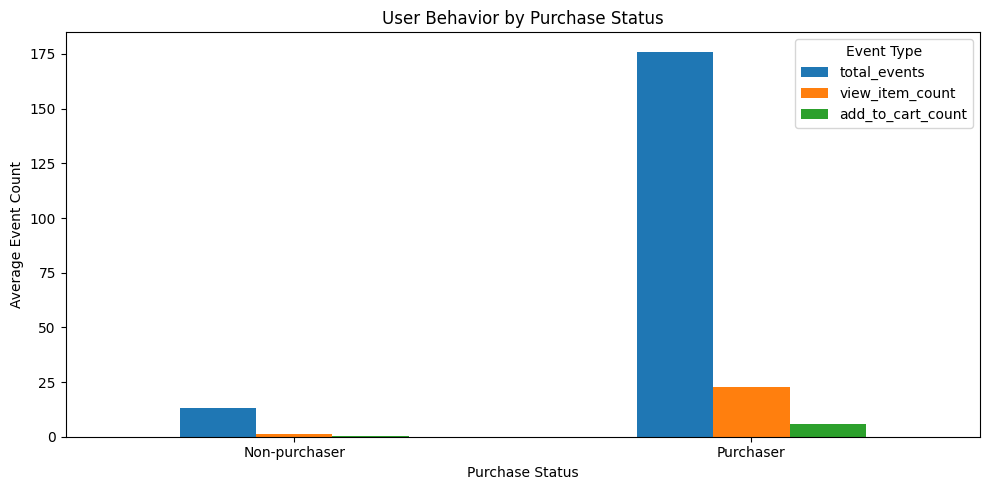

In [ ]:
import matplotlib.pyplot as plt

group_analysis.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('User Behavior by Purchase Status')
plt.xlabel('Purchase Status')
plt.ylabel('Average Event Count')
plt.xticks(
    ticks=[0, 1],
    labels=['Non-purchaser', 'Purchaser'],
    rotation=0
)

plt.legend(title='Event Type')
plt.tight_layout()
plt.show()

## 6. 분석 결과 요약

이번 분석에서는 GA4 공개 전자상거래 데이터를 기반으로 총 270,154명의 사용자 행동 데이터를 분석하였다.

기술통계를 통해 사용자별 이벤트 발생 현황을 확인하고, 구매 경험 여부에 따른 행동 차이를 비교하였다.

### 1. 사용자별 이벤트 발생 현황

- 전체 사용자 1인당 평균 이벤트 발생 횟수는 15.9회이며, 중앙값은 6회로 나타났다.
- 평균이 중앙값보다 높고 표준편차도 39.03으로 크게 나타나 사용자별 이벤트 발생 횟수에 상당한 편차가 있음을 확인하였다.
- 전체 이벤트 발생 횟수의 최댓값은 1,309회로, 일부 사용자가 다른 사용자보다 훨씬 많은 이벤트를 발생시킨 것으로 나타났다.

이를 통해 사용자별 활동 수준이 균등하지 않으며, 소수의 활동량이 많은 사용자가 전체 이벤트 발생량에 영향을 줄 가능성을 확인하였다.

### 2. 이벤트별 발생 현황

- 상품 조회 이벤트는 사용자당 평균 1.43회 발생했으며, 중앙값은 0회였다.
- 장바구니 추가 이벤트는 사용자당 평균 0.22회 발생했으며, 중앙값은 0회였다.
- 구매 이벤트는 사용자당 평균 0.02회 발생했으며, 중앙값은 0회였다.

대부분의 사용자는 상품 조회, 장바구니 추가, 구매 이벤트를 발생시키지 않았거나 적은 횟수만 발생시킨 것으로 나타났다.

특히 구매 이벤트의 평균 발생 횟수가 낮아 전체 사용자 중 구매 이벤트를 발생시킨 사용자는 상대적으로 적은 것으로 확인되었다.

### 3. 구매 여부에 따른 사용자 행동 비교

구매자와 비구매자의 평균 이벤트 발생 횟수를 비교한 결과 다음과 같은 차이가 나타났다.

| 분석 지표 | 비구매자 | 구매자 |
|---|---:|---:|
| 평균 전체 이벤트 | 13.24회 | 176.09회 |
| 평균 상품 조회 | 1.08회 | 22.63회 |
| 평균 장바구니 추가 | 0.12회 | 5.96회 |

- 구매자의 평균 전체 이벤트 발생 횟수는 비구매자보다 약 13.3배 높았다.
- 구매자의 평균 상품 조회 횟수는 비구매자보다 약 21배 높았다.
- 구매자의 평균 장바구니 추가 횟수는 비구매자보다 약 49.7배 높았다.

구매 경험이 있는 사용자는 비구매자보다 전체 이벤트 발생량뿐만 아니라 상품 조회 및 장바구니 추가 행동에서도 높은 수준을 보였다.

### 4. 종합 분석 결과

이번 분석을 통해 사용자별 이벤트 발생 수준에 큰 차이가 있으며, 구매 경험이 있는 사용자와 없는 사용자 사이에도 뚜렷한 행동 차이가 나타나는 것을 확인하였다.

특히 구매자는 비구매자보다 상품 조회와 장바구니 추가 활동이 활발한 것으로 나타났다. 이는 구매 경험이 있는 사용자 집단에서 상품 탐색 및 장바구니 관련 행동이 상대적으로 많이 관찰된다는 점을 보여준다.

다만 본 분석은 관측된 이벤트 데이터의 기술통계 및 그룹별 비교에 해당하며, 특정 행동이 구매를 유발했다는 인과관계를 의미하지 않는다.